PSO untuk Optimasi Rute Jaringan (Sederhana)

In [1]:
import numpy as np  # Mengimpor library NumPy untuk operasi numerik (array)
import matplotlib.pyplot as plt # Mengimpor library Matplotlib untuk membuat visualisasi (plot)

Fungsi Fitness

In [2]:
def fitness(x): # Mendefinisikan fungsi fitness yang akan dioptimasi
    delay = x[0]   # Komponen pertama dari vektor posisi partikel adalah delay
    energy = x[1]  # Komponen kedua dari vektor posisi partikel adalah energy
    return 0.6 * delay + 0.4 * energy  # Mengembalikan nilai fitness (semakin kecil semakin baik)

Inisialisasi Parameter PSO

In [3]:
num_particles = 5          # Jumlah partikel dalam swarm (kandidat rute)
num_dimensions = 2         # Dimensi masalah (delay dan energy)
max_iter = 20              # Jumlah iterasi maksimum untuk algoritma PSO
C1 = 2.0                   # Koefisien akselerasi personal (ke arah p_best)
C2 = 2.0                   # Koefisien akselerasi sosial (ke arah g_best)
w = 0.7                    # Faktor inersia untuk menjaga kecepatan sebelumnya

Inisialisasi Posisi & Kecepatan

In [4]:
# Menginisialisasi posisi partikel secara acak dalam rentang yang ditentukan
x = np.random.uniform(low=[8, 3], high=[15, 6], size=(num_particles, num_dimensions))
v = np.zeros_like(x)       # Menginisialisasi kecepatan partikel menjadi nol

Inisialisasi Personal Best & Global Best

In [5]:
p_best = x.copy() # Menginisialisasi personal best (posisi terbaik setiap partikel) dengan posisi awal
p_best_fitness = np.array([fitness(p) for p in p_best]) # Menghitung fitness untuk setiap personal best

g_best = p_best[np.argmin(p_best_fitness)] # Menentukan global best (posisi terbaik dari semua partikel) berdasarkan fitness terbaik
g_best_fitness = np.min(p_best_fitness) # Menyimpan nilai fitness dari global best

history = []  # List untuk menyimpan nilai fitness global terbaik di setiap iterasi

Iterasi PSO

In [6]:
for t in range(max_iter): # Loop utama iterasi PSO
    for i in range(num_particles): # Loop untuk setiap partikel
        r1, r2 = np.random.rand(), np.random.rand() # Menghasilkan angka acak antara 0 dan 1

        # Update kecepatan partikel
        v[i] = (
            w * v[i] # Komponen inersia (kecepatan sebelumnya)
            + C1 * r1 * (p_best[i] - x[i]) # Komponen kognitif (menuju personal best)
            + C2 * r2 * (g_best - x[i]) # Komponen sosial (menuju global best)
        )

        # Update posisi partikel
        x[i] = x[i] + v[i]

        # Hitung fitness untuk posisi partikel saat ini
        f = fitness(x[i])

        # Update personal best jika fitness saat ini lebih baik
        if f < p_best_fitness[i]:
            p_best[i] = x[i] # Simpan posisi baru sebagai personal best
            p_best_fitness[i] = f # Simpan nilai fitness baru personal best

    # Update global best setelah semua partikel diupdate
    min_index = np.argmin(p_best_fitness) # Cari indeks partikel dengan fitness personal best terbaik
    if p_best_fitness[min_index] < g_best_fitness: # Jika ada personal best yang lebih baik dari global best saat ini
        g_best = p_best[min_index] # Update global best dengan personal best tersebut
        g_best_fitness = p_best_fitness[min_index] # Update nilai fitness global best

    history.append(g_best_fitness) # Tambahkan nilai fitness global best ke history
    print(f"Iterasi {t+1:02d}: Global Best Fitness = {g_best_fitness:.4f}, Posisi = {g_best}") # Cetak hasil setiap iterasi

Iterasi 01: Global Best Fitness = 7.3321, Posisi = [9.1436708  4.61476682]
Iterasi 02: Global Best Fitness = 5.8808, Posisi = [6.521481   4.91966196]
Iterasi 03: Global Best Fitness = 0.3621, Posisi = [-2.73275336  5.00429456]
Iterasi 04: Global Best Fitness = -10.8840, Posisi = [-22.02583553   5.82882882]
Iterasi 05: Global Best Fitness = -29.6662, Posisi = [-54.70367908   7.89001275]
Iterasi 06: Global Best Fitness = -43.7275, Posisi = [-78.79057386   8.86718004]
Iterasi 07: Global Best Fitness = -58.7850, Posisi = [-104.94186991   10.45029951]
Iterasi 08: Global Best Fitness = -108.0976, Posisi = [-190.7227641    15.84003667]
Iterasi 09: Global Best Fitness = -178.3127, Posisi = [-313.02405299   23.75432595]
Iterasi 10: Global Best Fitness = -255.7946, Posisi = [-447.88464775   32.34055559]
Iterasi 11: Global Best Fitness = -472.9554, Posisi = [-826.05443226   56.69303806]
Iterasi 12: Global Best Fitness = -669.1085, Posisi = [-1167.67432152    78.74028133]
Iterasi 13: Global Best F

Visualisasi Hasil Konvergensi

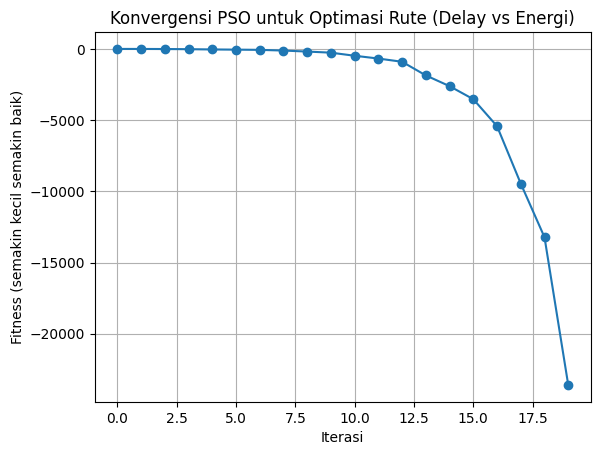

In [7]:
plt.plot(history, marker='o') # Membuat plot garis dari history fitness global terbaik
plt.title("Konvergensi PSO untuk Optimasi Rute (Delay vs Energi)") # Menambahkan judul plot
plt.xlabel("Iterasi") # Memberi label sumbu X
plt.ylabel("Fitness (semakin kecil semakin baik)") # Memberi label sumbu Y
plt.grid(True) # Menampilkan grid pada plot
plt.show() # Menampilkan plot